<>:42: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:42: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\ASUS\AppData\Local\Temp\ipykernel_46668\638314761.py:42: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  plt.axvspan(1, 3.2, color='green', alpha=0.05, label='Feasible region ($x \geq 1$)')


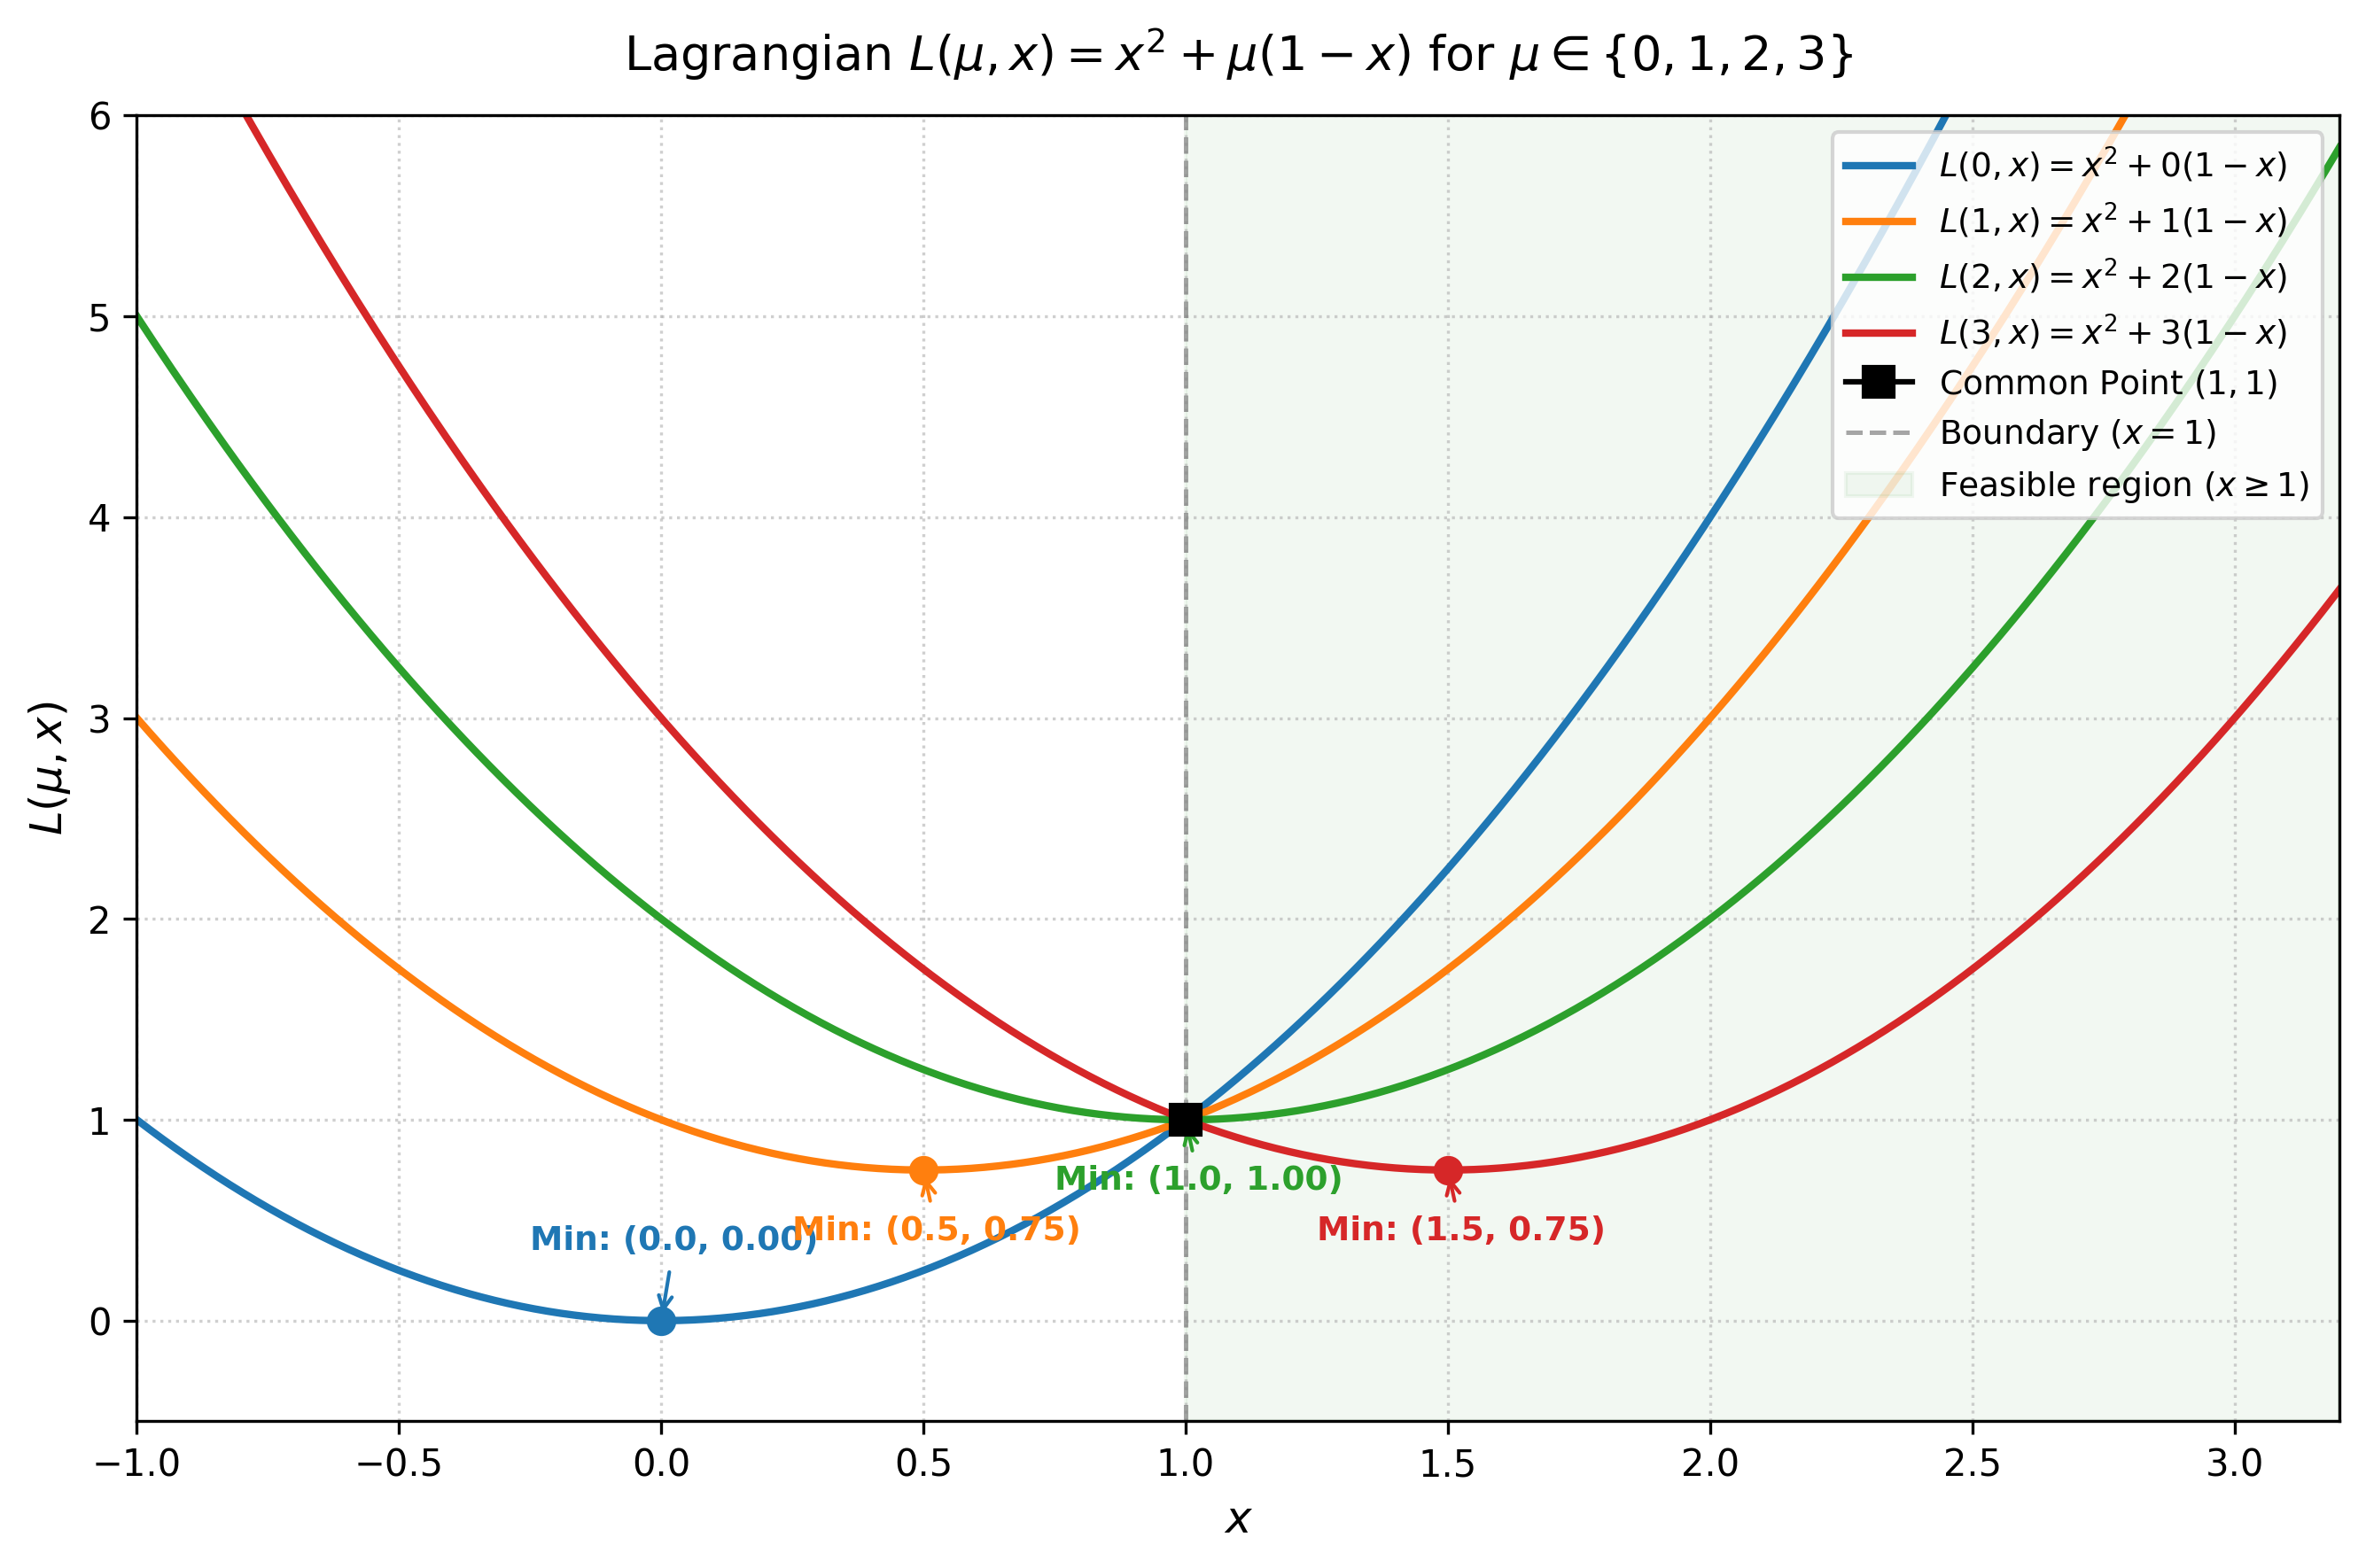

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define range for x and values for mu
x = np.linspace(-1.0, 3.2, 500)
mu_values = [0, 1, 2, 3]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # distinct colors

# 2. Define the Lagrangian function
def L(mu, x):
    return x**2 + mu * (1 - x)

# 3. Create the plot
plt.figure(figsize=(9, 6), dpi=300)

for mu, color in zip(mu_values, colors):
    # Compute L(mu, x)
    y = L(mu, x)
    plt.plot(x, y, label=rf'$L({mu}, x) = x^2 + {mu}(1-x)$', color=color, linewidth=2)
    
    # Calculate minimizer x(mu) and minimum value L(mu, x(mu))
    x_min = mu / 2.0
    y_min = L(mu, x_min)
    
    # Plot and annotate the minimizer
    plt.plot(x_min, y_min, marker='o', markersize=7, color=color)
    plt.annotate(
        f'Min: ({x_min:.1f}, {y_min:.2f})',
        xy=(x_min, y_min),
        xytext=(x_min - 0.25, y_min - 0.35 if mu != 0 else y_min + 0.35),
        fontsize=9,
        fontweight='semibold',
        color=color,
        arrowprops=dict(arrowstyle='->', color=color, lw=1)
    )

# 4. Highlight the common intersection point (1, 1)
plt.plot(1, 1, marker='s', markersize=8, color='black', zorder=5, label='Common Point $(1, 1)$')

# 5. Feasible region boundary line (x >= 1)
plt.axvline(x=1, color='gray', linestyle='--', linewidth=1.2, alpha=0.7, label='Boundary ($x = 1$)')
plt.axvspan(1, 3.2, color='green', alpha=0.05, label='Feasible region ($x \geq 1$)')

# 6. Formatting and labels
plt.title(r'Lagrangian $L(\mu, x) = x^2 + \mu(1-x)$ for $\mu \in \{0, 1, 2, 3\}$', fontsize=13, pad=12)
plt.xlabel(r'$x$', fontsize=12)
plt.ylabel(r'$L(\mu, x)$', fontsize=12)
plt.xlim(-1.0, 3.2)
plt.ylim(-0.5, 6.0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=9)

# 7. Layout adjustment and save
plt.tight_layout()
plt.savefig('q1a_lagrangian_plot.png')
plt.show()

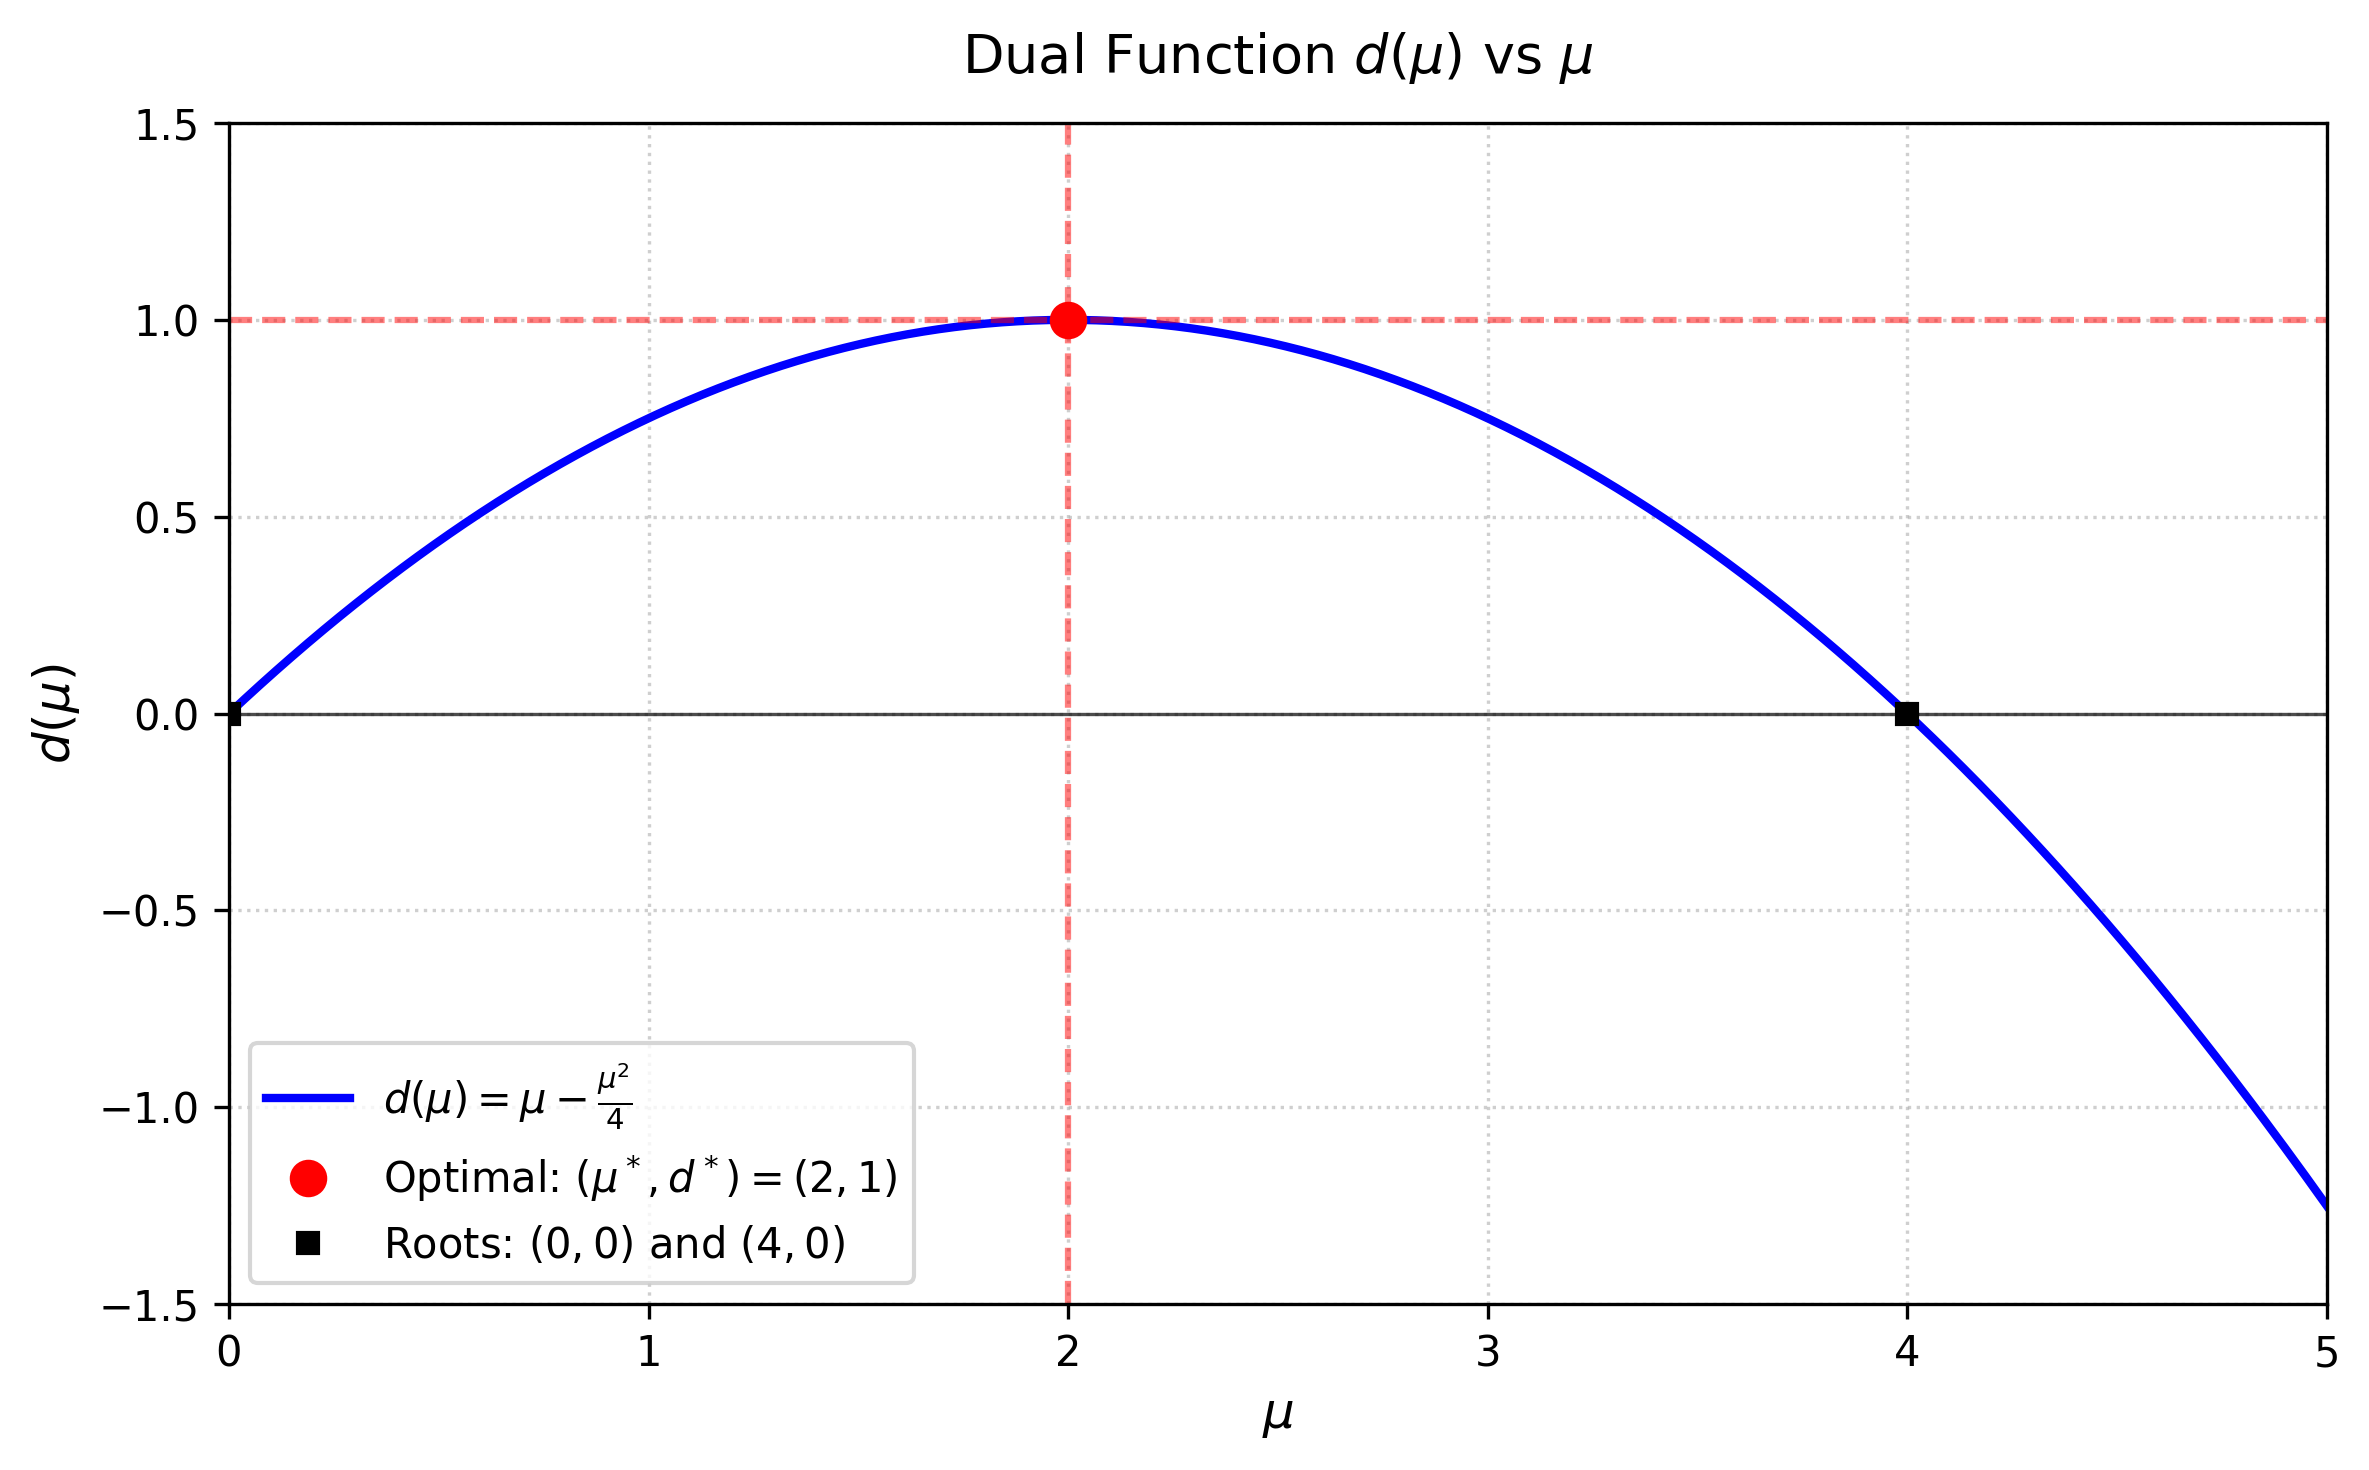

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Define mu range (mu >= 0)
mu = np.linspace(0, 5, 400)

# Dual function d(mu) = mu - mu^2 / 4
d = mu - (mu**2) / 4.0

plt.figure(figsize=(8, 5), dpi=300)
plt.plot(mu, d, 'b-', linewidth=2, label=r'$d(\mu) = \mu - \frac{\mu^2}{4}$')

# Mark optimal point (mu*, d*)
mu_star = 2.0
d_star = 1.0
plt.plot(mu_star, d_star, 'ro', markersize=8, label=rf'Optimal: $(\mu^*, d^*) = ({mu_star:.0f}, {d_star:.0f})$')

# Annotations and reference lines
plt.axvline(x=mu_star, color='red', linestyle='--', alpha=0.5)
plt.axhline(y=d_star, color='red', linestyle='--', alpha=0.5)
plt.axhline(y=0, color='black', linewidth=0.8, alpha=0.7)

# Mark roots
plt.plot([0, 4], [0, 0], 'ks', markersize=5, label='Roots: $(0, 0)$ and $(4, 0)$')

plt.title(r'Dual Function $d(\mu)$ vs $\mu$', fontsize=13, pad=12)
plt.xlabel(r'$\mu$', fontsize=12)
plt.ylabel(r'$d(\mu)$', fontsize=12)
plt.xlim(0, 5)
plt.ylim(-1.5, 1.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig('q1b_dual_function.png')
plt.show()

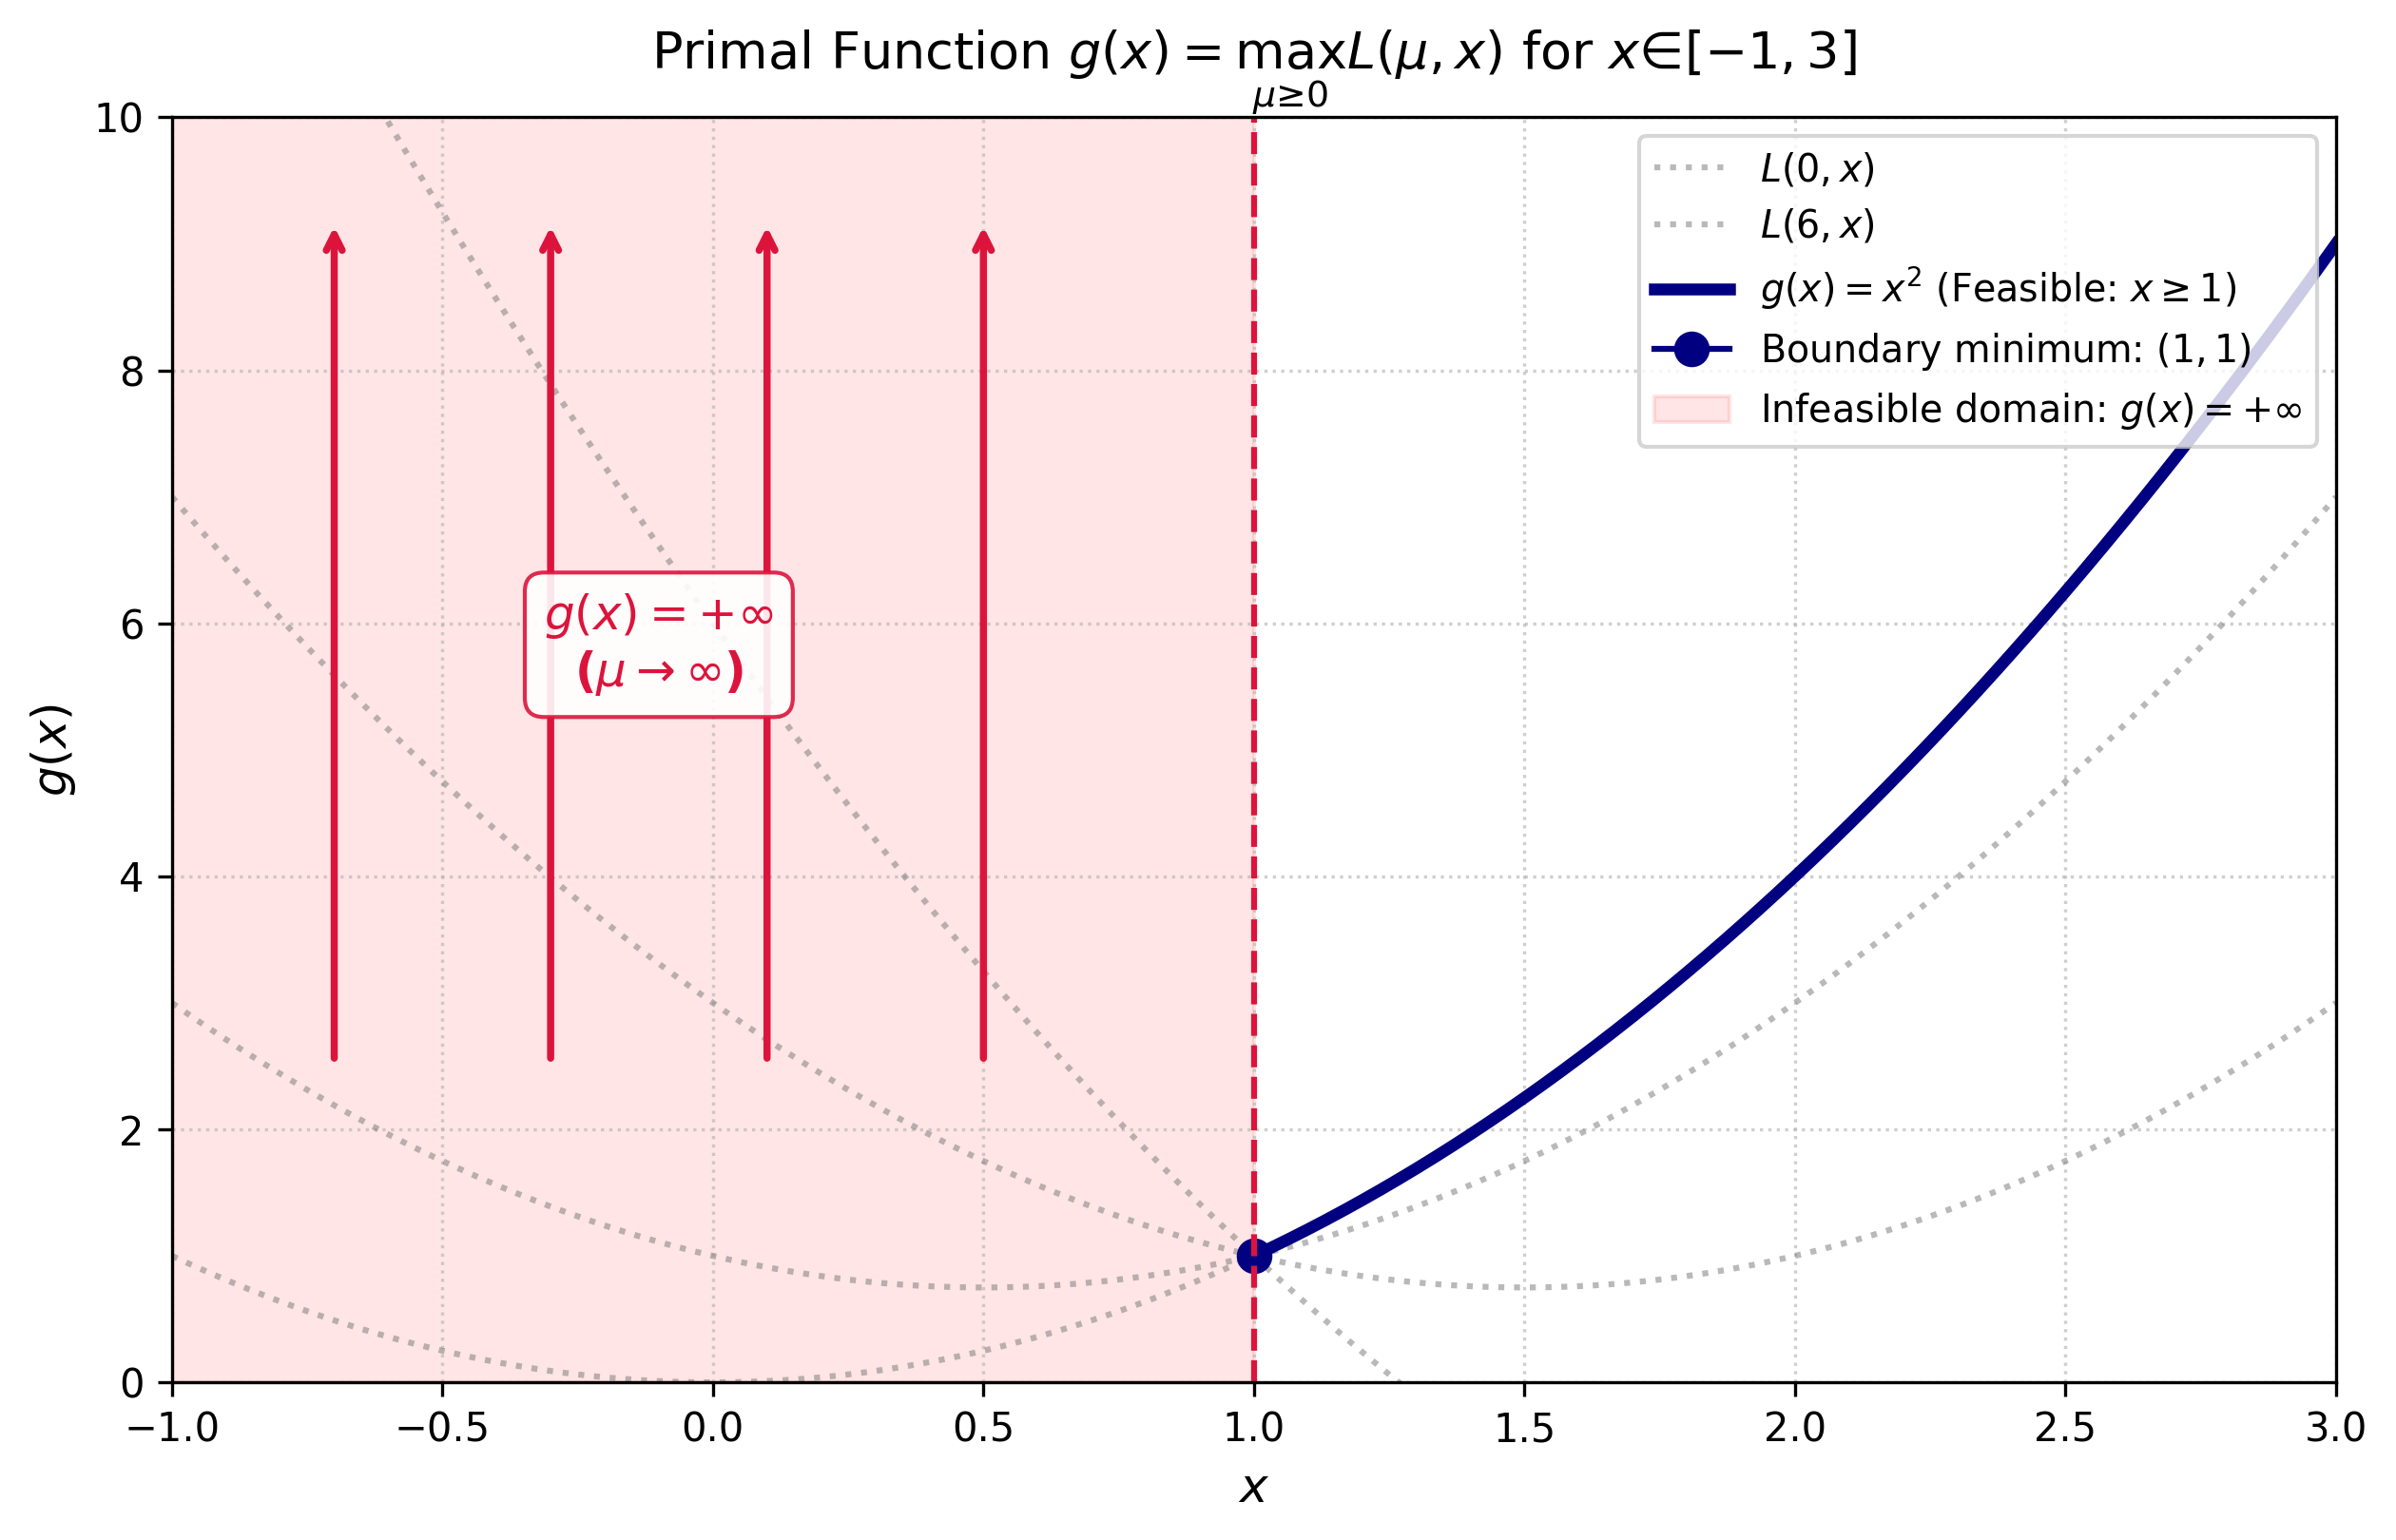

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup grid
x_all = np.linspace(-1.0, 3.0, 500)
x_feas = np.linspace(1.0, 3.0, 300)

plt.figure(figsize=(8.5, 5.5), dpi=300)

# 2. Draw background curves L(mu, x) to illustrate upper envelope
mu_vals = [0, 1, 3, 6]
for mu in mu_vals:
    plt.plot(x_all, x_all**2 + mu * (1 - x_all), ':', color='gray', alpha=0.55,
             label=rf'$L({mu}, x)$' if mu in [0, 6] else "")

# 3. Plot feasible part of g(x): g(x) = x^2 for x >= 1
plt.plot(x_feas, x_feas**2, color='navy', linewidth=3, 
         label=r'$g(x) = x^2$ (Feasible: $x \geq 1$)')

# 4. Mark boundary and optimal solution at (1, 1)
plt.plot(1, 1, marker='o', markersize=8, color='navy', label=r'Boundary minimum: $(1, 1)$')

# 5. Represent infeasible region x < 1 where g(x) = +infinity
plt.axvspan(-1.0, 1.0, color='red', alpha=0.10, label=r'Infeasible domain: $g(x) = +\infty$')
plt.axvline(x=1.0, color='crimson', linestyle='--', linewidth=1.5)

# Upward arrows showing growth towards +infinity for x < 1
for arrow_x in [-0.7, -0.3, 0.1, 0.5]:
    plt.annotate('', xy=(arrow_x, 9.2), xytext=(arrow_x, 2.5),
                 arrowprops=dict(arrowstyle='->', color='crimson', lw=1.8))

# Text annotation in the infeasible zone
plt.text(-0.1, 5.5, r'$g(x) = +\infty$' + '\n' + r'($\mu \rightarrow \infty$)', 
         color='crimson', fontsize=12, fontweight='bold', ha='center',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='crimson', alpha=0.9))

# 6. Formatting (using \geq instead of \ge)
plt.title(r'Primal Function $g(x) = \max_{\mu \geq 0} L(\mu, x)$ for $x \in [-1, 3]$', fontsize=13, pad=12)
plt.xlabel(r'$x$', fontsize=12)
plt.ylabel(r'$g(x)$', fontsize=12)
plt.xlim(-1.0, 3.0)
plt.ylim(0, 10.0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig('q1c_primal_function.png')
plt.show()

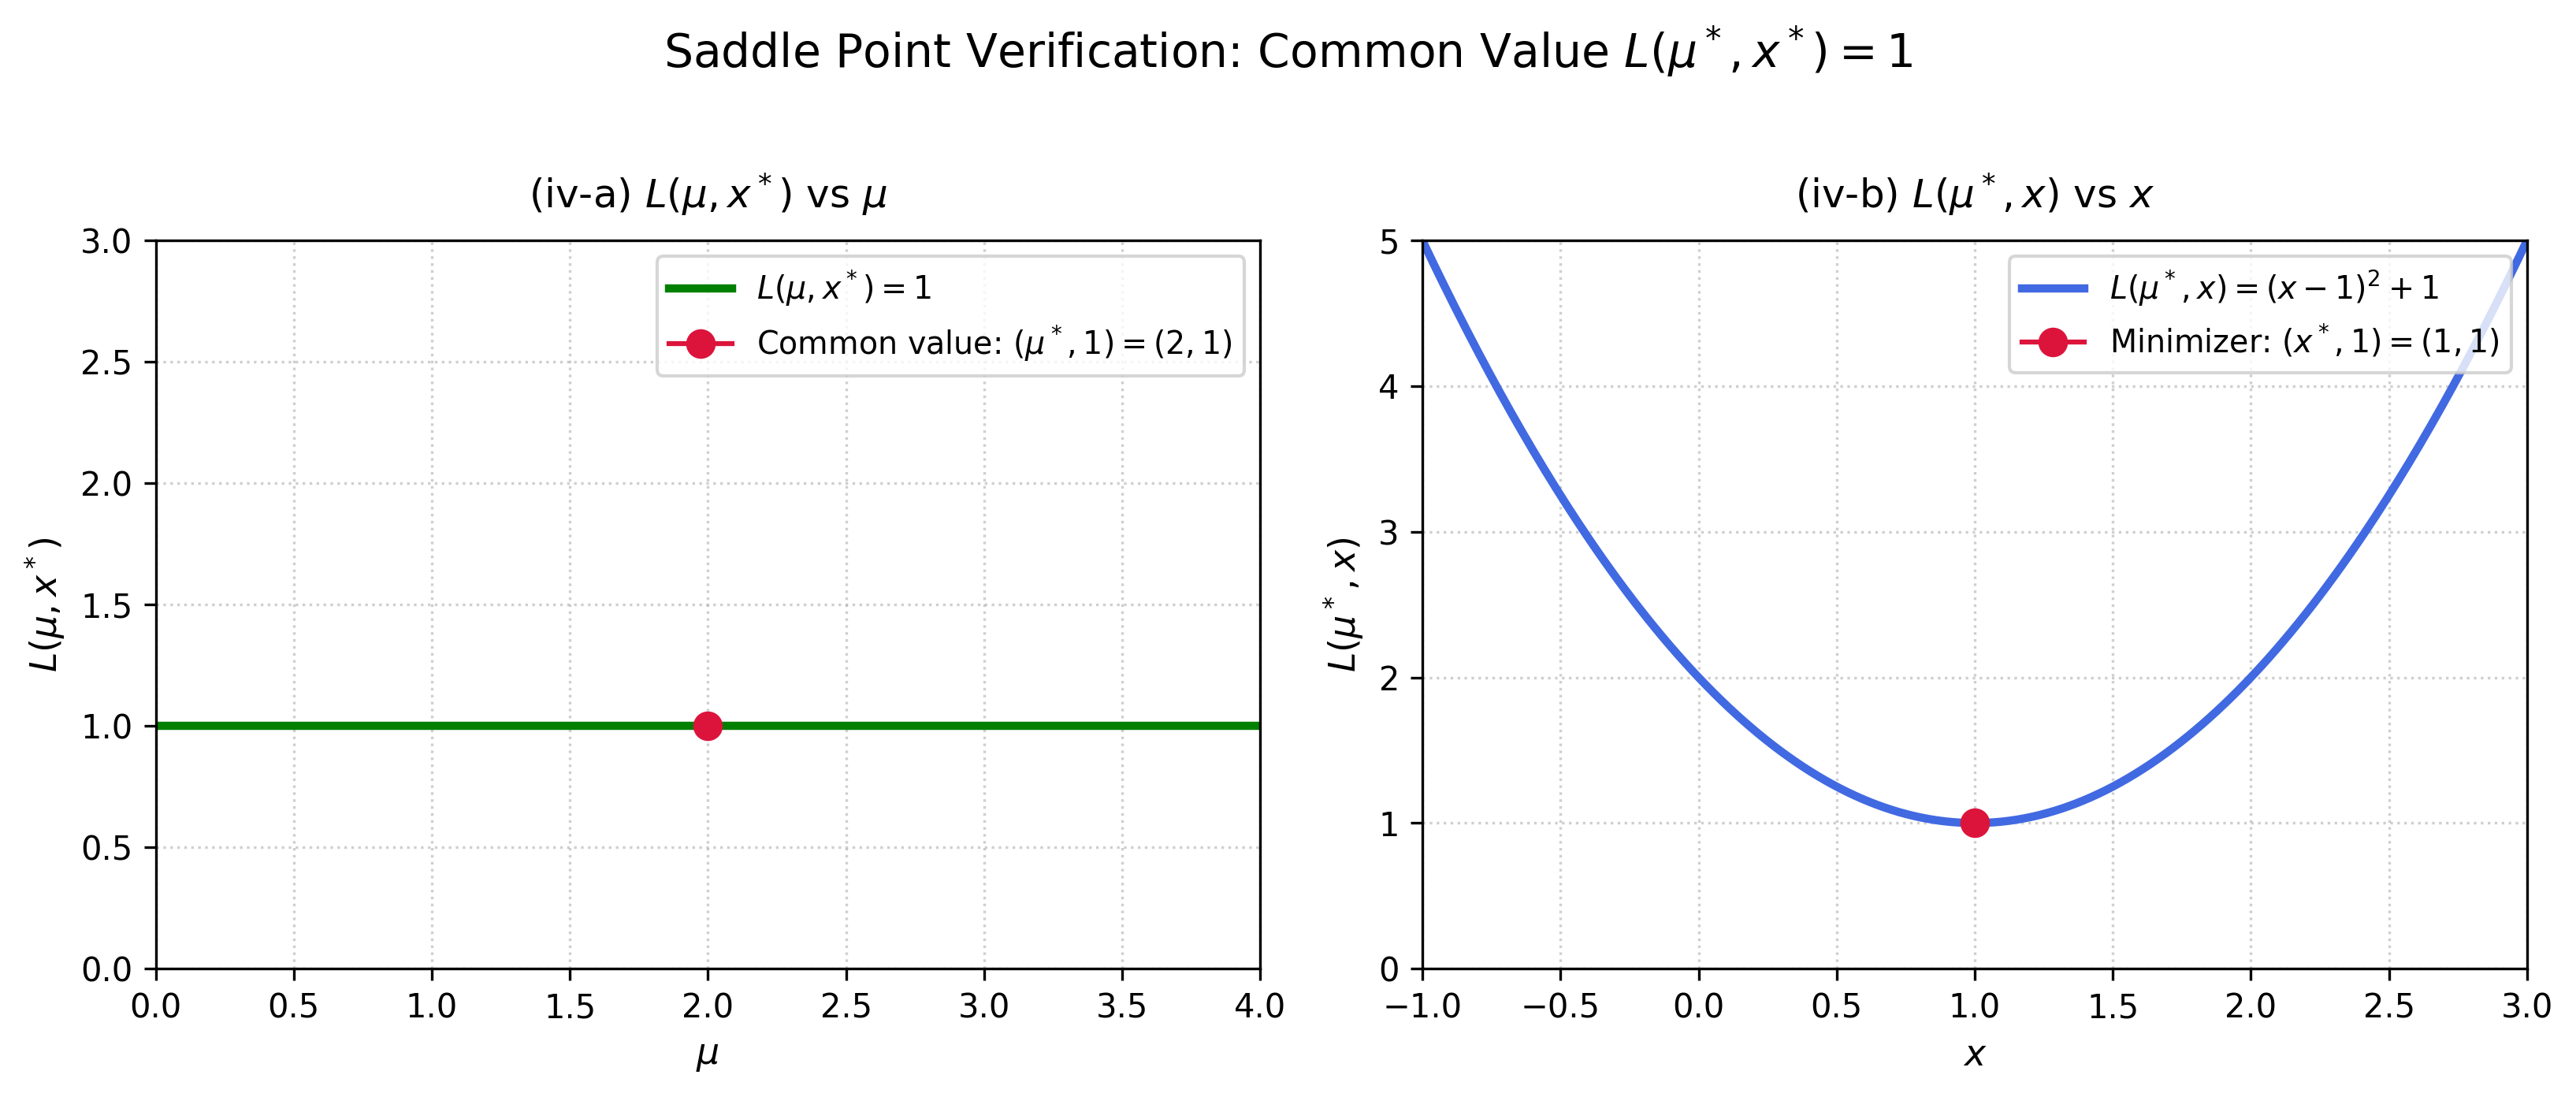

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Create figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)

# ----------------- Subplot 1: L(mu, x*) vs mu -----------------
mu = np.linspace(0, 4, 300)
L_mu_xstar = np.ones_like(mu)  # L(mu, 1) = 1 for all mu

ax1.plot(mu, L_mu_xstar, color='green', linewidth=2.5, label=r'$L(\mu, x^*) = 1$')
ax1.plot(2, 1, marker='o', markersize=8, color='crimson', label=r'Common value: $(\mu^*, 1) = (2, 1)$')

ax1.set_title(r'(iv-a) $L(\mu, x^*)$ vs $\mu$', fontsize=12, pad=10)
ax1.set_xlabel(r'$\mu$', fontsize=11)
ax1.set_ylabel(r'$L(\mu, x^*)$', fontsize=11)
ax1.set_xlim(0, 4)
ax1.set_ylim(0, 3)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)

# Annotate that it is constant
# ----------------- Subplot 2: L(mu*, x) vs x -----------------
x = np.linspace(-1, 3, 300)
L_mustar_x = (x - 1)**2 + 1  # L(2, x) = (x-1)^2 + 1

ax2.plot(x, L_mustar_x, color='royalblue', linewidth=2.5, label=r'$L(\mu^*, x) = (x - 1)^2 + 1$')
ax2.plot(1, 1, marker='o', markersize=8, color='crimson', label=r'Minimizer: $(x^*, 1) = (1, 1)$')

ax2.set_title(r'(iv-b) $L(\mu^*, x)$ vs $x$', fontsize=12, pad=10)
ax2.set_xlabel(r'$x$', fontsize=11)
ax2.set_ylabel(r'$L(\mu^*, x)$', fontsize=11)
ax2.set_xlim(-1, 3)
ax2.set_ylim(0, 5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)

# Annotate minimum at vertex

plt.suptitle(r'Saddle Point Verification: Common Value $L(\mu^*, x^*) = 1$', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('q2a_saddle_point.png', bbox_inches='tight')
plt.show()

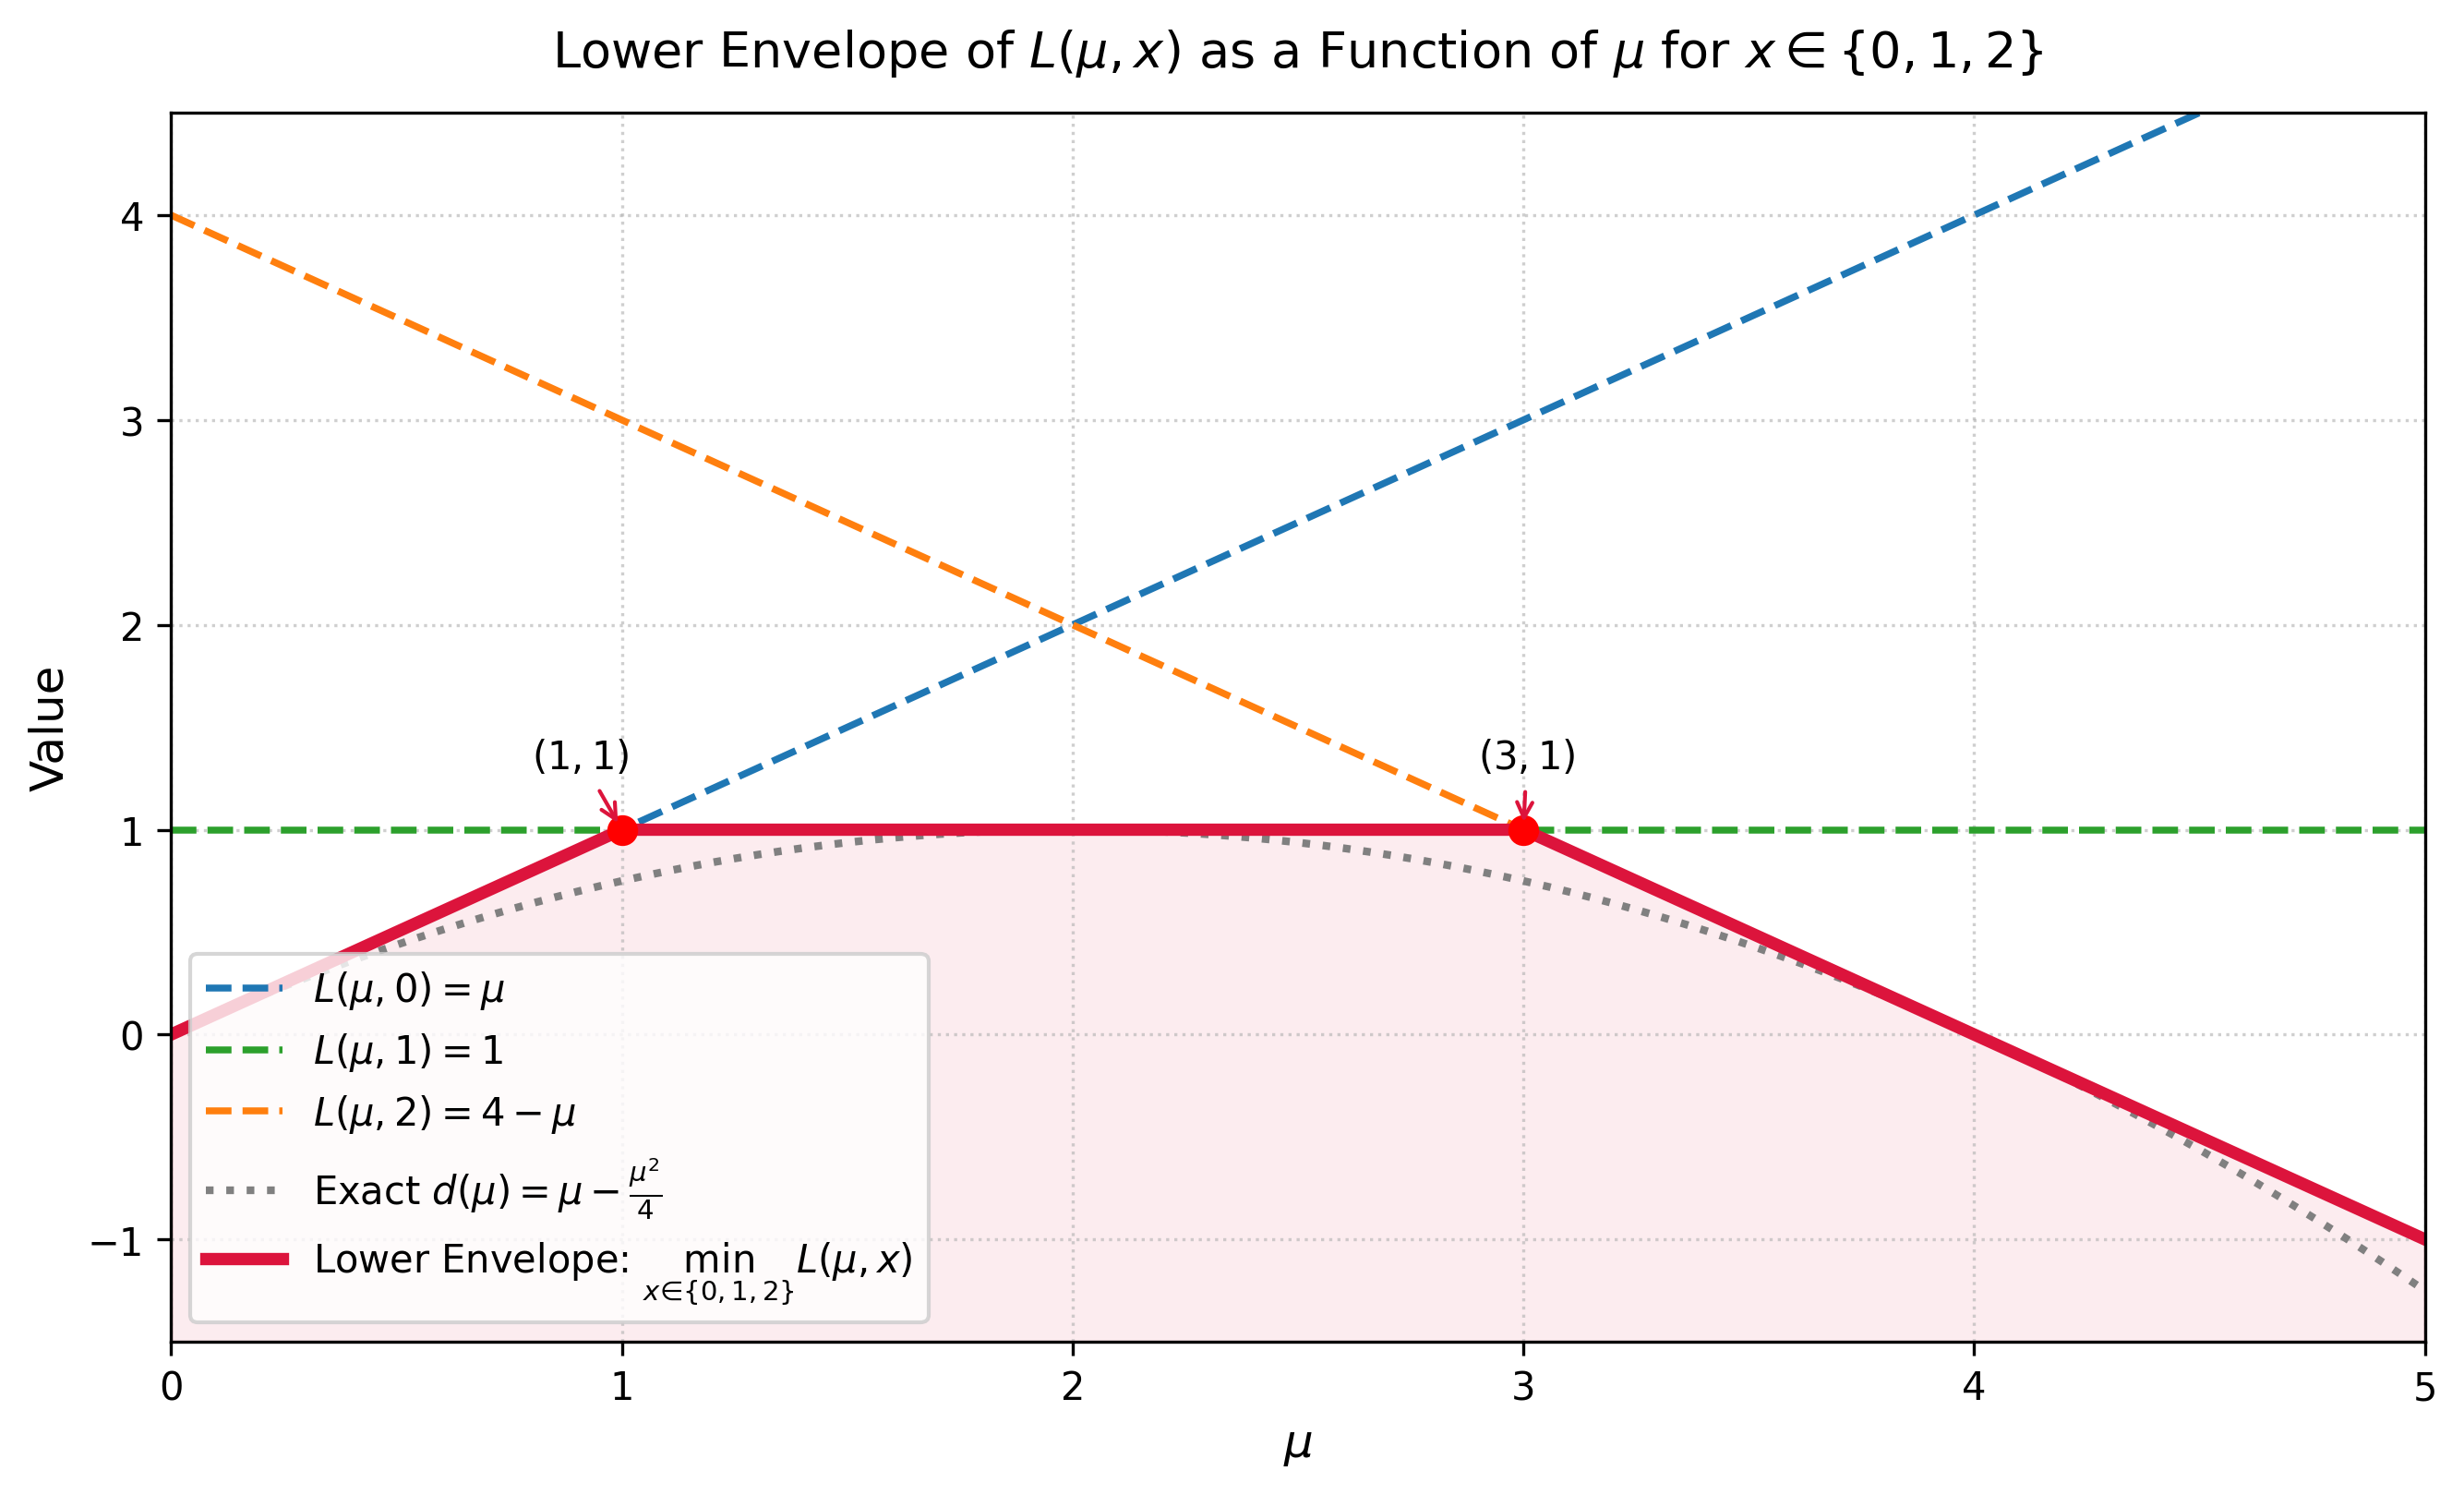

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Define mu domain
mu = np.linspace(0, 5, 400)

# The three linear functions
L0 = mu            # x = 0
L1 = np.ones_like(mu)  # x = 1
L2 = 4.0 - mu      # x = 2

# Lower envelope of the three lines
lower_env = np.minimum(np.minimum(L0, L1), L2)

# Exact dual function from Q1(b) for comparison
d_exact = mu - (mu**2) / 4.0

plt.figure(figsize=(9, 5.5), dpi=300)

# 1. Plot the three individual straight lines
plt.plot(mu, L0, '--', color='#1f77b4', linewidth=1.8, label=r'$L(\mu, 0) = \mu$')
plt.plot(mu, L1, '--', color='#2ca02c', linewidth=1.8, label=r'$L(\mu, 1) = 1$')
plt.plot(mu, L2, '--', color='#ff7f0e', linewidth=1.8, label=r'$L(\mu, 2) = 4 - \mu$')

# 2. Plot exact dual function
plt.plot(mu, d_exact, ':', color='gray', linewidth=2, label=r'Exact $d(\mu) = \mu - \frac{\mu^2}{4}$')

# 3. Highlight the lower envelope
plt.plot(mu, lower_env, color='crimson', linewidth=3.2, 
         label=r'Lower Envelope: $\min_{x \in \{0, 1, 2\}} L(\mu, x)$')

# Fill below lower envelope to emphasize hypograph/concavity
plt.fill_between(mu, -1.5, lower_env, color='crimson', alpha=0.08)

# 4. Mark corner points of the envelope
plt.plot([1, 3], [1, 1], 'ro', markersize=7)
plt.annotate(r'$(1, 1)$', xy=(1, 1), xytext=(0.8, 1.3),
             arrowprops=dict(arrowstyle='->', color='crimson'))
plt.annotate(r'$(3, 1)$', xy=(3, 1), xytext=(2.9, 1.3),
             arrowprops=dict(arrowstyle='->', color='crimson'))

# Formatting
plt.title(r'Lower Envelope of $L(\mu, x)$ as a Function of $\mu$ for $x \in \{0, 1, 2\}$', fontsize=13, pad=12)
plt.xlabel(r'$\mu$', fontsize=12)
plt.ylabel(r'Value', fontsize=12)
plt.xlim(0, 5)
plt.ylim(-1.5, 4.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig('q3b_lower_envelope.png')
plt.show()